# Assignment 3; EV adoption through a network stag hunt approach
### Lisa Castricum, Ditmer de Heer & Nicky Kroon

In [17]:
# Requirements
!pip install -r requirements.txt

## 1. Baseline System Analysis

In [18]:
# Importing the necessary libraries
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

In [34]:
# Importing the modules from the provided .py files
project_module_path = os.path.join(os.getcwd(), "Assignment 3 helper files")
if project_module_path not in sys.path:
    sys.path.append(project_module_path)

from ev_core import EVStagHuntModel, set_initial_adopters

In [20]:
# Setting up the parameters.
N = 200
T = 150
a0 = 1.0
b = 1.0
beta_I = 2.5
g_I = 0.1
update_rule = "imitate"

# 2D parameter sweep set up.
grid_size = 20
X0_values = np.linspace(0.0, 1.0, grid_size)
I0_values = np.linspace(0.0, 1.0, grid_size)

# Small ensemble per grid point, to get a better estimate of overall adoption.
ensemble_size = 5

# Seed for reproducibility.
seed_base = 42

In [21]:
# Function to run the baseline analysis, it uses some functions from the ev_core.py file.
def run_baseline_trial(X0_frac: float, I0: float, seed: int) -> float:
    """Runs one complete-graph analysis and returns final adoption X(T)."""

    # Initialize the EVStagHuntModel with the given parameters.
    model = EVStagHuntModel(
        initial_ev=0,
        a0=a0,
        beta_I=beta_I,
        b=b,
        g_I=g_I,
        I0=float(I0),
        seed=seed,
        network_type="fully_connected",
        n_nodes=N,
        p=1.0,
        collect=False,
        strategy_choice_func=update_rule,
    )

    # Randomly selecting the initial adopters.
    set_initial_adopters(model, X0_frac, method="random", seed=seed)

    # Early stopping once converged
    prev_x = None
    stable_steps = 0
    for _ in range(T):
        model.step()
        x = model.get_adoption_fraction()
        if prev_x is not None and abs(x - prev_x) < 1e-12:
            stable_steps += 1
        else:
            stable_steps = 0
        prev_x = x
        if x in (0.0, 1.0) and stable_steps >= 2:
            break

    return model.get_adoption_fraction()

In [22]:
# Sweeps and tracks seeds used at each (X0, I0).
X_final = np.zeros((len(I0_values), len(X0_values)))
seed_log = {}

# Loop over all the combinations of I0 and X0 values to run the baseline analysis.
for i, I0 in enumerate(I0_values):
    for j, X0 in enumerate(X0_values):
        seeds = [seed_base + (i * len(X0_values) + j) * 100 + k for k in range(ensemble_size)]
        seed_log[(float(X0), float(I0))] = seeds
        finals = [run_baseline_trial(float(X0), float(I0), seed=s) for s in seeds]
        X_final[i, j] = float(np.mean(finals))

# Tidying the results into a DataFrame.
heatmap_df = pd.DataFrame(
    [
        (float(X0), float(I0), float(X_final[i, j]))
        for i, I0 in enumerate(I0_values)
        for j, X0 in enumerate(X0_values)
    ],
    columns=["X0", "I0", "X_star"],
)

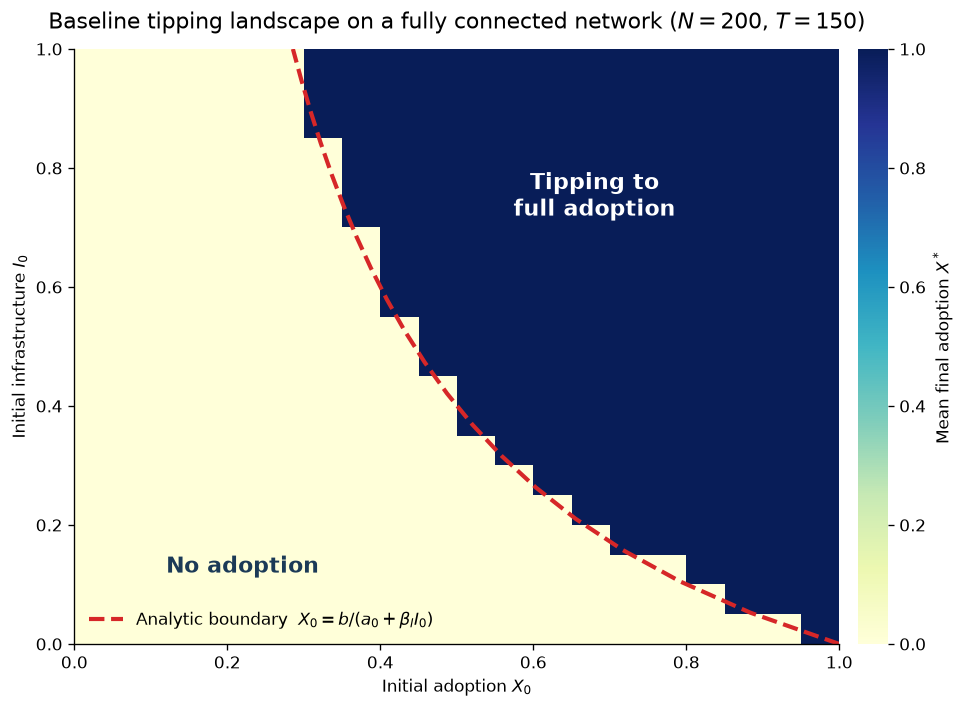

Tracked seeds for repeatability (first 5 grid points):
(X0=0.000, I0=0.000) -> [42, 43, 44, 45, 46]
(X0=0.053, I0=0.000) -> [142, 143, 144, 145, 146]
(X0=0.105, I0=0.000) -> [242, 243, 244, 245, 246]
(X0=0.158, I0=0.000) -> [342, 343, 344, 345, 346]
(X0=0.211, I0=0.000) -> [442, 443, 444, 445, 446]


,X0,I0,X_star
0,0.000000,0.0,0.0
1,0.052632,0.0,0.0
2,0.105263,0.0,0.0
3,0.157895,0.0,0.0
4,0.210526,0.0,0.0


In [30]:
# Analytic tipping boundary: X*_{crit}(I) = b / (a0 + beta_I * I)
# Computation for the tipping point based on initial infrastructure I0
x_threshold = np.clip(b / (a0 + beta_I * I0_values), 0.0, 1.0)

plt.style.use("default")
fig, ax = plt.subplots(figsize=(8.5, 6), dpi=120)

im = ax.imshow(
    X_final,
    origin="lower",
    extent=[X0_values[0], X0_values[-1], I0_values[0], I0_values[-1]],
    aspect="auto",
    vmin=0, vmax=1,
    cmap="YlGnBu",
)

# Analytic boundary
ax.plot(x_threshold, I0_values, color="#d62728", ls="--", lw=2.5,
        label=r"Analytic boundary  $X_0 = b/(a_0+\beta_I I_0)$")

# Labelling the two regimes directly
ax.text(0.12, 0.12, "No adoption", fontsize=13, color="#1b3a57", weight="bold")
ax.text(0.68, 0.72, "Tipping to\nfull adoption", fontsize=13, color="white",
        weight="bold", ha="center")

# Colorbar for the heatmap
cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label("Mean final adoption $X^*$")
cbar.outline.set_visible(False)

# Setting axis labels, limits, and title.
ax.set(xlabel="Initial adoption $X_0$", ylabel="Initial infrastructure $I_0$",
       xlim=(0, 1), ylim=(0, 1))
ax.set_title("Baseline tipping landscape on a fully connected network ($N=200$, $T=150$)",
             fontsize=13, pad=12)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(loc="lower left", frameon=False)

fig.tight_layout()
plt.show()

# Displaying the first few tracked seeds for repeatability.
print("Tracked seeds for repeatability (first 5 grid points):")
for idx, ((x0, i0), seeds) in enumerate(seed_log.items()):
    if idx >= 5:
        break
    print(f"(X0={x0:.3f}, I0={i0:.3f}) -> {seeds}")

heatmap_df.head()

In [33]:
# Saving the seed log for repeatability
import json
with open("seed_log.json", "w") as f:
    # Ensuring that keys are strings for JSON compatibility
    json_compatible_seed_log = {str(k): v for k, v in seed_log.items()}
    f.write(json.dumps(json_compatible_seed_log))
print("Seed log saved to seed_log.json")

Seed log saved to seed_log.json
